# Prédiction du temps de livraison : régression linéaire

**Objectif :** prédire le temps de livraison d'une commande (`Delivery_Time_min`, en minutes) à partir de sa distance, de la météo, du trafic, du type de véhicule, etc.

C'est un problème de **régression** (la valeur à prédire est un nombre, pas une catégorie).

**Démarche :**
1. Explorer les données (EDA)
2. Séparer en train / test, puis nettoyer, encoder et standardiser
3. Comparer un modèle de référence (la moyenne) à une régression linéaire
4. Refaire la régression linéaire avec une descente de gradient (SGD)
5. Interpréter les coefficients et analyser les erreurs

## 1. Imports et chargement des données

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, SGDRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    root_mean_squared_error,
    r2_score,
)

df = pd.read_csv("../data/raw/Food_Delivery_Times.csv")
print(df.head())

   Order_ID  Distance_km Weather Traffic_Level Time_of_Day Vehicle_Type  \
0       522         7.93   Windy           Low   Afternoon      Scooter   
1       738        16.42   Clear        Medium     Evening         Bike   
2       741         9.52   Foggy           Low       Night      Scooter   
3       661         7.44   Rainy        Medium   Afternoon      Scooter   
4       412        19.03   Clear           Low     Morning         Bike   

   Preparation_Time_min  Courier_Experience_yrs  Delivery_Time_min  
0                    12                     1.0                 43  
1                    20                     2.0                 84  
2                    28                     1.0                 59  
3                     5                     1.0                 37  
4                    16                     5.0                 68  


## 2. Exploration des données (EDA)

In [2]:
print(df.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Order_ID                1000 non-null   int64  
 1   Distance_km             1000 non-null   float64
 2   Weather                 970 non-null    str    
 3   Traffic_Level           970 non-null    str    
 4   Time_of_Day             970 non-null    str    
 5   Vehicle_Type            1000 non-null   str    
 6   Preparation_Time_min    1000 non-null   int64  
 7   Courier_Experience_yrs  970 non-null    float64
 8   Delivery_Time_min       1000 non-null   int64  
dtypes: float64(2), int64(3), str(4)
memory usage: 70.4 KB
None


`info()` montre que **30 valeurs manquantes** (3 %) existent dans 4 colonnes : `Weather`, `Traffic_Level`, `Time_of_Day` et `Courier_Experience_yrs`. On les traitera à l'étape 4.

In [3]:
print(df.describe())

          Order_ID  Distance_km  Preparation_Time_min  Courier_Experience_yrs  \
count  1000.000000  1000.000000           1000.000000              970.000000   
mean    500.500000    10.059970             16.982000                4.579381   
std     288.819436     5.696656              7.204553                2.914394   
min       1.000000     0.590000              5.000000                0.000000   
25%     250.750000     5.105000             11.000000                2.000000   
50%     500.500000    10.190000             17.000000                5.000000   
75%     750.250000    15.017500             23.000000                7.000000   
max    1000.000000    19.990000             29.000000                9.000000   

       Delivery_Time_min  
count        1000.000000  
mean           56.732000  
std            22.070915  
min             8.000000  
25%            41.000000  
50%            55.500000  
75%            71.000000  
max           153.000000  


In [4]:
print(df.isnull().sum())

Order_ID                   0
Distance_km                0
Weather                   30
Traffic_Level             30
Time_of_Day               30
Vehicle_Type               0
Preparation_Time_min       0
Courier_Experience_yrs    30
Delivery_Time_min          0
dtype: int64


In [5]:
print(df.duplicated().sum())

0


Pas de doublons. Répartition des variables catégorielles :

In [6]:
categorical_columns = df.select_dtypes(exclude="number").columns
for col in categorical_columns:
    print(f"\n--- {col} ---")
    print(df[col].value_counts())


--- Weather ---
Weather
Clear    470
Rainy    204
Foggy    103
Snowy     97
Windy     96
Name: count, dtype: int64

--- Traffic_Level ---
Traffic_Level
Medium    390
Low       383
High      197
Name: count, dtype: int64

--- Time_of_Day ---
Time_of_Day
Morning      308
Evening      293
Afternoon    284
Night         85
Name: count, dtype: int64

--- Vehicle_Type ---
Vehicle_Type
Bike       503
Scooter    302
Car        195
Name: count, dtype: int64


### Distribution du temps de livraison

Un histogramme montre **comment les valeurs sont réparties** dans le dataset.

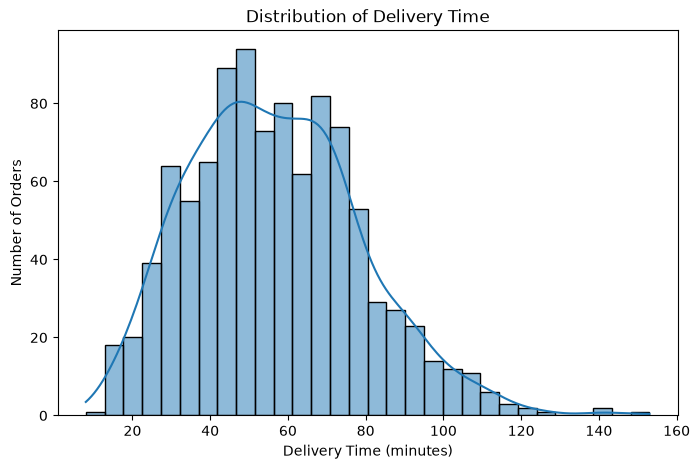

In [7]:
plt.figure(figsize=(8, 5))

sns.histplot(df["Delivery_Time_min"], bins=30, kde=True)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Time (minutes)")
plt.ylabel("Number of Orders")

plt.show()

Les temps de livraison vont d'environ 10 à 150 minutes, avec une médiane autour de 55 minutes. La distribution est un peu étalée vers la droite : quelques livraisons sont très longues.

### Distance et temps de livraison

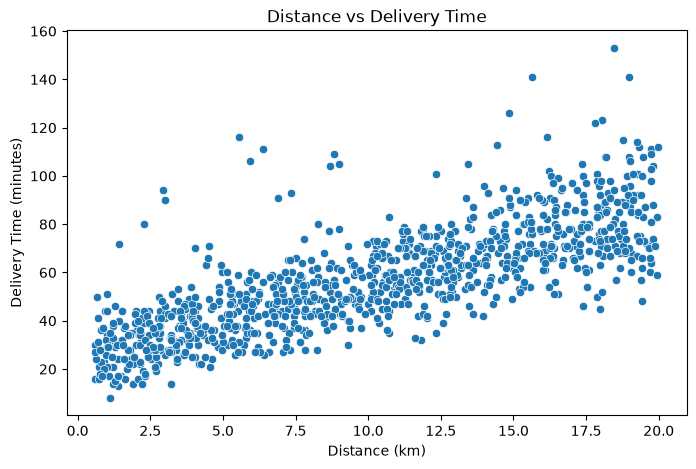

In [8]:
plt.figure(figsize=(8, 5))

sns.scatterplot(
    data=df,
    x="Distance_km",
    y="Delivery_Time_min"
)

plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (minutes)")

plt.show()

Plus la distance augmente, plus le temps de livraison augmente : la relation est globalement **linéaire**, ce qui justifie l'utilisation d'une régression linéaire. Quelques points s'écartent beaucoup de la tendance (livraisons très longues pour une courte distance).

### Valeurs extrêmes

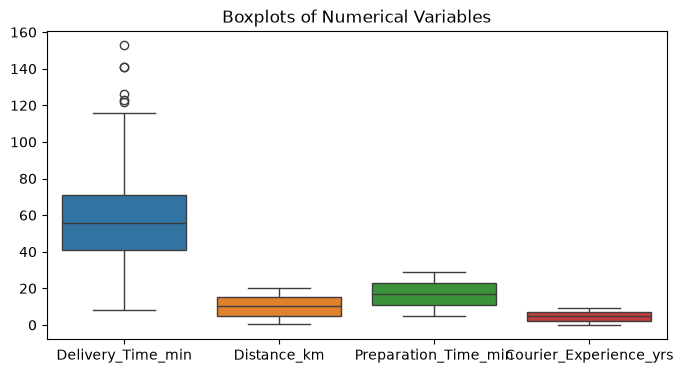

In [9]:
plt.figure(figsize=(8, 4))

sns.boxplot(data=df[[
    "Delivery_Time_min",
    "Distance_km",
    "Preparation_Time_min",
    "Courier_Experience_yrs"
]])

plt.title("Boxplots of Numerical Variables")

plt.show()

Le temps de livraison présente quelques valeurs extrêmes (au-dessus d'environ 115 minutes). On remarque aussi que les variables n'ont **pas la même échelle**, d'où la standardisation à l'étape 5.

## 3. Séparation train / test

On garde 20 % des commandes de côté (**test**) : le modèle ne les voit jamais pendant l'entraînement, ce qui permet de mesurer sa vraie performance. `Order_ID` est retiré car c'est seulement un identifiant.

In [10]:
X = df.drop(columns=["Order_ID", "Delivery_Time_min"])
y = df["Delivery_Time_min"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("y_train:", y_train.shape, "| y_test:", y_test.shape)

X_train: (800, 7) | X_test: (200, 7)
y_train: (800,) | y_test: (200,)


## 4. Remplir les valeurs manquantes

On remplace les valeurs manquantes par la **médiane** (variable numérique) ou la **valeur la plus fréquente** (variable catégorielle). Ces valeurs sont calculées **sur le train uniquement**, puis appliquées au test : sinon le modèle recevrait des informations du test (*fuite de données*, ou *data leakage*).

In [11]:
X_train = X_train.copy()
X_test = X_test.copy()

# Expérience du livreur : médiane du train
median_exp = X_train["Courier_Experience_yrs"].median()
X_train["Courier_Experience_yrs"] = X_train["Courier_Experience_yrs"].fillna(median_exp)
X_test["Courier_Experience_yrs"] = X_test["Courier_Experience_yrs"].fillna(median_exp)

# Colonnes catégorielles : valeur la plus fréquente du train
for col in ["Weather", "Traffic_Level", "Time_of_Day"]:
    mode_value = X_train[col].mode()[0]
    X_train[col] = X_train[col].fillna(mode_value)
    X_test[col] = X_test[col].fillna(mode_value)

print("Valeurs manquantes (train):", X_train.isnull().sum().sum())
print("Valeurs manquantes (test) :", X_test.isnull().sum().sum())

Valeurs manquantes (train): 0
Valeurs manquantes (test) : 0


## 5. Encodage et standardisation

- **`OneHotEncoder`** : transforme chaque catégorie en colonne 0/1. Avec `drop="first"`, une catégorie est supprimée pour servir de **référence** (météo claire, trafic élevé, après-midi, vélo).
- **`StandardScaler`** : met les variables numériques à la même échelle (moyenne 0, écart-type 1).

Comme avant, on apprend ces transformations sur le train (`fit`) puis on les applique au test (`transform`).

In [12]:
numeric_cols = ["Distance_km", "Preparation_Time_min", "Courier_Experience_yrs"]
categorical_cols = ["Weather", "Traffic_Level", "Time_of_Day", "Vehicle_Type"]

encoder = OneHotEncoder(drop="first", sparse_output=False)
X_train_cat = encoder.fit_transform(X_train[categorical_cols])
X_test_cat = encoder.transform(X_test[categorical_cols])

scaler = StandardScaler()
X_train_num = scaler.fit_transform(X_train[numeric_cols])
X_test_num = scaler.transform(X_test[numeric_cols])

X_train_final = np.hstack([X_train_num, X_train_cat])
X_test_final = np.hstack([X_test_num, X_test_cat])

feature_names = numeric_cols + list(encoder.get_feature_names_out(categorical_cols))

print("X_train_final:", X_train_final.shape)
print("X_test_final :", X_test_final.shape)

X_train_final: (800, 14)
X_test_final : (200, 14)


## 6. Modèle de référence

Avant de tester un vrai modèle, on construit une **référence** très simple : toujours prédire la moyenne du temps de livraison. Tout modèle utile doit faire mieux. Les résultats de cette référence sont affichés avec ceux de la régression linéaire juste en dessous.

Métriques utilisées :
- **MAE** : erreur moyenne en minutes (la plus facile à comprendre)
- **RMSE** : comme la MAE, mais pénalise davantage les grosses erreurs
- **MSE** : le RMSE au carré
- **R²** : part de la variabilité expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne)

In [13]:
def evaluate(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": root_mean_squared_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred),
        "R2": r2_score(y_true, y_pred),
    }

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train_final, y_train)

results = {"Baseline (moyenne) - test": evaluate(y_test, baseline.predict(X_test_final))}

## 7. Régression linéaire

In [14]:
model = LinearRegression()
model.fit(X_train_final, y_train)

y_pred_train = model.predict(X_train_final)
y_pred = model.predict(X_test_final)

results["LinearRegression - train"] = evaluate(y_train, y_pred_train)
results["LinearRegression - test"] = evaluate(y_test, y_pred)

pd.DataFrame(results).T.round(2)

,MAE,RMSE,MSE,R2
Baseline (moyenne) - test,17.50,21.23,450.82,-0.01
LinearRegression - train,6.65,10.89,118.68,0.76
LinearRegression - test,6.06,8.95,80.14,0.82


La régression linéaire fait nettement mieux que la référence :
- **MAE de 6,06 minutes** (contre 17,5 pour la référence) : en moyenne, la prédiction se trompe d'environ 6 minutes.
- **R² de 0,82** : le modèle explique 82 % de la variabilité du temps de livraison (contre -0,01 pour la référence).

Le score est même meilleur sur le test que sur le train (R² 0,82 contre 0,76). Ce n'est pas un signe de sur-apprentissage : avec seulement 200 commandes de test, le résultat dépend un peu du découpage et peut être légèrement plus favorable.

### Coefficients

In [15]:
coefficients = pd.Series(model.coef_, index=feature_names)
print(coefficients.sort_values(key=abs, ascending=False).round(2))

Distance_km               17.19
Traffic_Level_Low        -10.68
Weather_Snowy              9.28
Preparation_Time_min       7.02
Weather_Foggy              5.70
Traffic_Level_Medium      -5.58
Weather_Rainy              4.63
Courier_Experience_yrs    -1.98
Weather_Windy              1.61
Time_of_Day_Night         -1.30
Time_of_Day_Evening        1.00
Vehicle_Type_Scooter      -0.86
Vehicle_Type_Car           0.60
Time_of_Day_Morning       -0.19
dtype: float64


- **La distance** est la variable la plus influente : environ +17 minutes pour chaque écart-type en plus (soit environ 5,7 km).
- **Le trafic** : un trafic faible fait gagner environ 10,7 minutes par rapport à un trafic élevé.
- **La météo** : par rapport à un temps clair, la neige ajoute environ 9 minutes, le brouillard environ 6 et la pluie environ 5.
- **La préparation** ajoute environ 7 minutes par écart-type (environ 7 minutes de préparation en plus).
- Le type de véhicule, le moment de la journée et l'expérience du livreur ont un effet bien plus faible.

### Analyse des erreurs

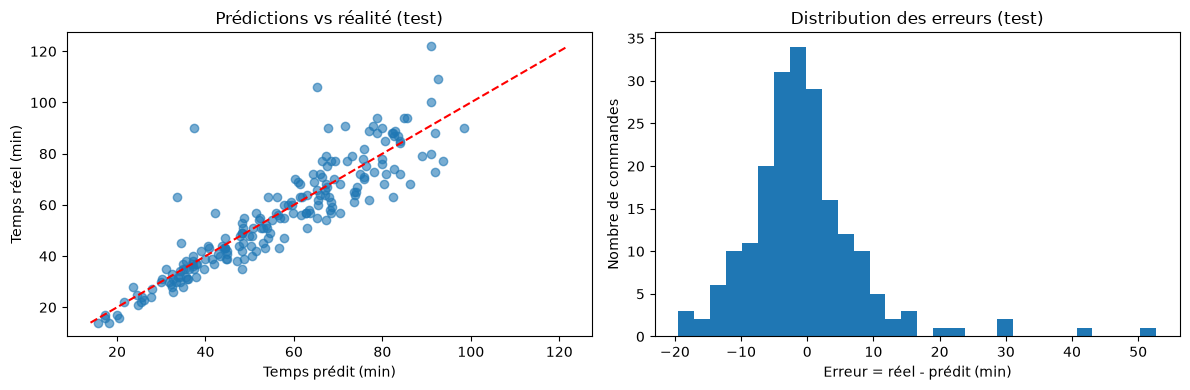

Erreurs de plus de 20 min : 5 sur 200


In [16]:
residuals = y_test - y_pred

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].scatter(y_pred, y_test, alpha=0.6)
lims = [min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max())]
axes[0].plot(lims, lims, color="red", linestyle="--")
axes[0].set_xlabel("Temps prédit (min)")
axes[0].set_ylabel("Temps réel (min)")
axes[0].set_title("Prédictions vs réalité (test)")

axes[1].hist(residuals, bins=30)
axes[1].set_xlabel("Erreur = réel - prédit (min)")
axes[1].set_ylabel("Nombre de commandes")
axes[1].set_title("Distribution des erreurs (test)")

plt.tight_layout()
plt.show()

print("Erreurs de plus de 20 min :", (residuals.abs() > 20).sum(), "sur", len(residuals))

Les prédictions suivent bien la diagonale rouge (prédiction parfaite) et les erreurs sont centrées autour de 0. Les 5 grosses erreurs (plus de 20 minutes) sont des livraisons beaucoup **plus longues que prévu**, du même type que les valeurs extrêmes vues dans l'EDA : le modèle ne peut pas les anticiper avec les variables disponibles.

## 8. Descente de gradient (SGD)

La régression linéaire classique calcule la solution exacte en une seule fois. La **descente de gradient** s'en approche **pas à pas** : à chaque itération, elle ajuste légèrement les coefficients pour réduire l'erreur (MSE). Le paramètre `eta0` est la taille de chaque pas.

On suit ici l'erreur sur 100 itérations (*epochs*).

In [17]:
sgd_model = SGDRegressor(
    loss="squared_error",
    learning_rate="constant",
    eta0=0.001,
    random_state=42
)

train_losses = []
test_losses = []

for i in range(100):
    sgd_model.partial_fit(X_train_final, y_train)
    train_losses.append(mean_squared_error(y_train, sgd_model.predict(X_train_final)))
    test_losses.append(mean_squared_error(y_test, sgd_model.predict(X_test_final)))

print("Loss train : début =", round(train_losses[0], 1), "-> fin =", round(train_losses[-1], 1))
print("Loss test : début =", round(test_losses[0], 1), "-> fin =", round(test_losses[-1], 1))
print("La loss train a diminué :", train_losses[-1] < train_losses[0])

Loss train : début = 491.2 -> fin = 118.9
Loss test : début = 436.2 -> fin = 80.0
La loss train a diminué : True


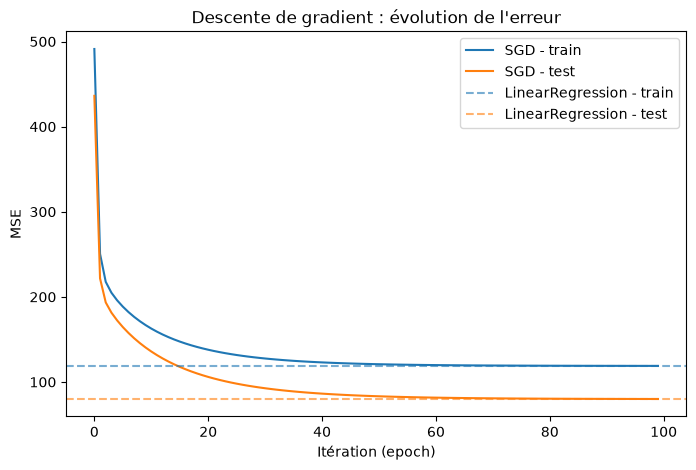

In [18]:
lr_train_mse = mean_squared_error(y_train, y_pred_train)
lr_test_mse = mean_squared_error(y_test, y_pred)

plt.figure(figsize=(8, 5))
plt.plot(train_losses, label="SGD - train")
plt.plot(test_losses, label="SGD - test")
plt.axhline(lr_train_mse, color="C0", linestyle="--", alpha=0.6, label="LinearRegression - train")
plt.axhline(lr_test_mse, color="C1", linestyle="--", alpha=0.6, label="LinearRegression - test")
plt.xlabel("Itération (epoch)")
plt.ylabel("MSE")
plt.title("Descente de gradient : évolution de l'erreur")
plt.legend()
plt.show()

L'erreur chute très vite au début, puis se stabilise et **rejoint celle de la régression linéaire** (lignes pointillées). La descente de gradient converge donc vers la même solution, ce qui est attendu pour une régression linéaire.

### Tableau final

In [19]:
results["SGD - train"] = evaluate(y_train, sgd_model.predict(X_train_final))
results["SGD - test"] = evaluate(y_test, sgd_model.predict(X_test_final))

pd.DataFrame(results).T.round(2)

,MAE,RMSE,MSE,R2
Baseline (moyenne) - test,17.50,21.23,450.82,-0.01
LinearRegression - train,6.65,10.89,118.68,0.76
LinearRegression - test,6.06,8.95,80.14,0.82
SGD - train,6.62,10.90,118.88,0.76
SGD - test,6.01,8.94,79.99,0.82
